# 04 - Artifact detectors (milestone 5)

`PROJECT_PLAN.md` §6-7: window features on PhysioMotion (plus simulated
pops), the 128 Hz and 250 Hz detectors (LightGBM, LDA, RBF SVM) with
participant-grouped 5-fold CV, and the transfer test on the held-out
phantom pool. Same code as `scripts/07_extract_features.py`,
`08_train_detectors.py` and `09_phantom_transfer.py`
(`adr.detection.*`).

Feature extraction and training are slow (tens of minutes), so by default
this notebook **loads the saved results**; set the flags below to recompute.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from adr.config import load_paths, package_versions, seed_everything

logging.basicConfig(level=logging.INFO, format="%(message)s", force=True)
pd.set_option("display.max_columns", 50, "display.width", 200)
paths = load_paths()
seed_everything()
package_versions()

{'python': '3.14.8',
 'numpy': '2.5.4',
 'scipy': '1.18.1',
 'pandas': '3.0.6',
 'mne': '1.13.2',
 'scikit-learn': '1.9.1',
 'lightgbm': '4.7.0',
 'xgboost': '3.4.2',
 'eelbrain': '0.43.0b0',
 'matplotlib': '3.11.2',
 'mne-icalabel': '0.10.0'}

In [2]:
from adr.detection import features, train, transfer
from adr.detection.dataset import run_features
from adr.preprocessing.channels import detector_channels

RUN_TRAINING = False   # True: re-run CV and refit/save the frozen models (slow; raw variant)
RUN_TRANSFER = False   # True: recompute the phantom transfer test (a few minutes per variant)
RUN_DATASET1 = False   # True: recompute flag rates on clean Dataset I (a few minutes)
det_dir = paths["results"] / "detectors"

## Features for one run

Window features at 128 Hz for PhysioMotion sub-1 run 1 (cached after the
first computation), and how one feature separates the classes.

(2503, 685) | bad channels interpolated: [np.str_('AF4')] | pop examples: 83
rest windows: 479 | kept as clean: 447 (blinky eyes-open rest windows dropped)


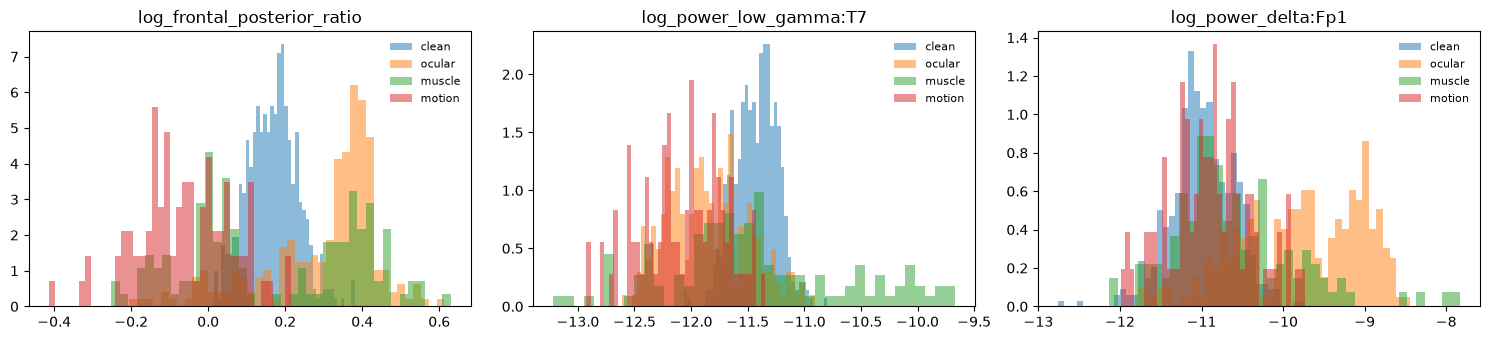

In [3]:
f = run_features(1, 1, 128.0)
names = features.feature_names(detector_channels(), 128.0)
X = pd.DataFrame(f["X"], columns=names)
print(X.shape, "| bad channels interpolated:", list(f["bads"]), "| pop examples:", len(f["X_pop"]))
clean = f["rest"] & (f["fp_ptp_uv"] <= features.detection_config()["clean_max_frontal_ptp_uv"])
print("rest windows:", f["rest"].sum(), "| kept as clean:", clean.sum(), "(blinky eyes-open rest windows dropped)")
label = np.select([f["ocular"], f["muscle"], f["motion"], clean], ["ocular", "muscle", "motion", "clean"], "excluded")
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, feat in zip(axes, ["log_frontal_posterior_ratio", "log_power_low_gamma:T7", "log_power_delta:Fp1"]):
    for cls in ("clean", "ocular", "muscle", "motion"):
        ax.hist(X.loc[label == cls, feat], bins=40, alpha=0.5, density=True, label=cls)
    ax.set_title(feat); ax.legend(frameon=False, fontsize=8)
fig.tight_layout()

## Cross-validated results (participant-grouped 5-fold)

In [4]:
if RUN_TRAINING:
    tables = []
    for fs in (128.0, 250.0):
        data = train.load_rate(fs)
        tables.append(train.cross_validate(fs, data=data))
        tables[-1].to_csv(train.output_dir(fs) / "cv_metrics.csv", index=False)
        train.fit_final(fs, data=data)
raw = pd.concat([pd.read_csv(det_dir / f"{r}Hz" / "cv_metrics.csv") for r in (128, 250)]).assign(variant="raw")
cv = raw.copy()
cv.round(3)

,rate,model,target,pr_auc,roc_auc,f1,sensitivity,specificity,n_pos,n_neg,event_sensitivity,false_alarms_per_hour,variant
0,128,lightgbm,artifact,0.970,0.945,0.895,0.919,0.777,57490,34534,0.977,527.689,raw
1,128,lightgbm,ocular,0.923,0.956,0.845,0.885,0.904,28763,63261,0.985,371.321,raw
2,128,lightgbm,muscle,0.871,0.953,0.756,0.788,0.940,15476,76548,0.871,121.550,raw
3,128,lightgbm,motion,0.887,0.951,0.778,0.864,0.903,19717,72307,0.992,263.949,raw
4,128,lightgbm,pop,0.866,0.969,0.828,0.849,0.984,6830,85194,NaN,NaN,raw
5,128,lda,artifact,0.945,0.898,0.849,0.796,0.868,57490,34534,0.941,453.049,raw
6,128,lda,ocular,0.879,0.937,0.811,0.861,0.881,28763,63261,0.965,376.116,raw
7,128,lda,muscle,0.801,0.921,0.692,0.755,0.914,15476,76548,0.886,228.505,raw
8,128,lda,motion,0.764,0.908,0.696,0.810,0.859,19717,72307,0.969,369.028,raw
9,128,lda,pop,0.258,0.770,0.266,0.657,0.736,6830,85194,NaN,NaN,raw


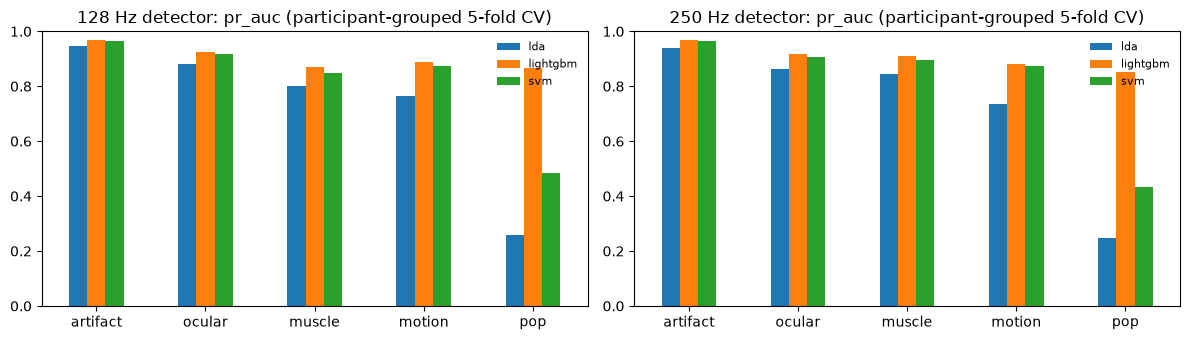

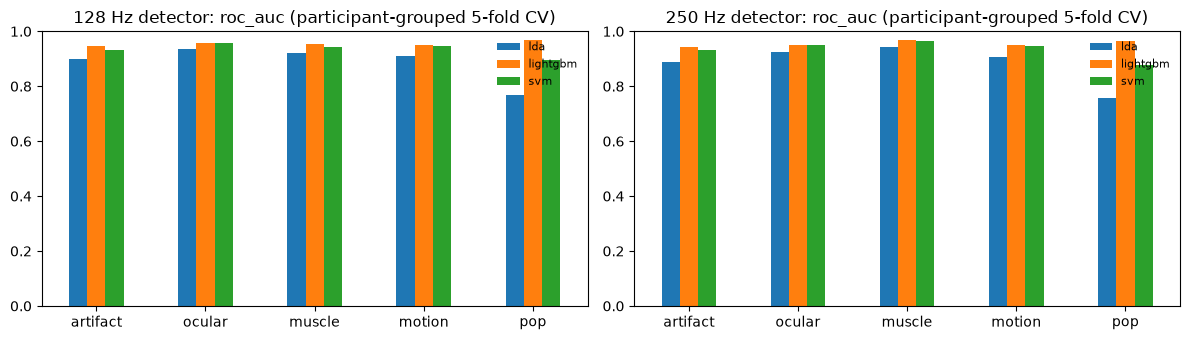

In [5]:
fig = train.plot_cv(cv, "pr_auc")
fig = train.plot_cv(cv, "roc_auc")

## What the main detector uses

Top LightGBM feature importances (gain) for the frozen 128 Hz models.

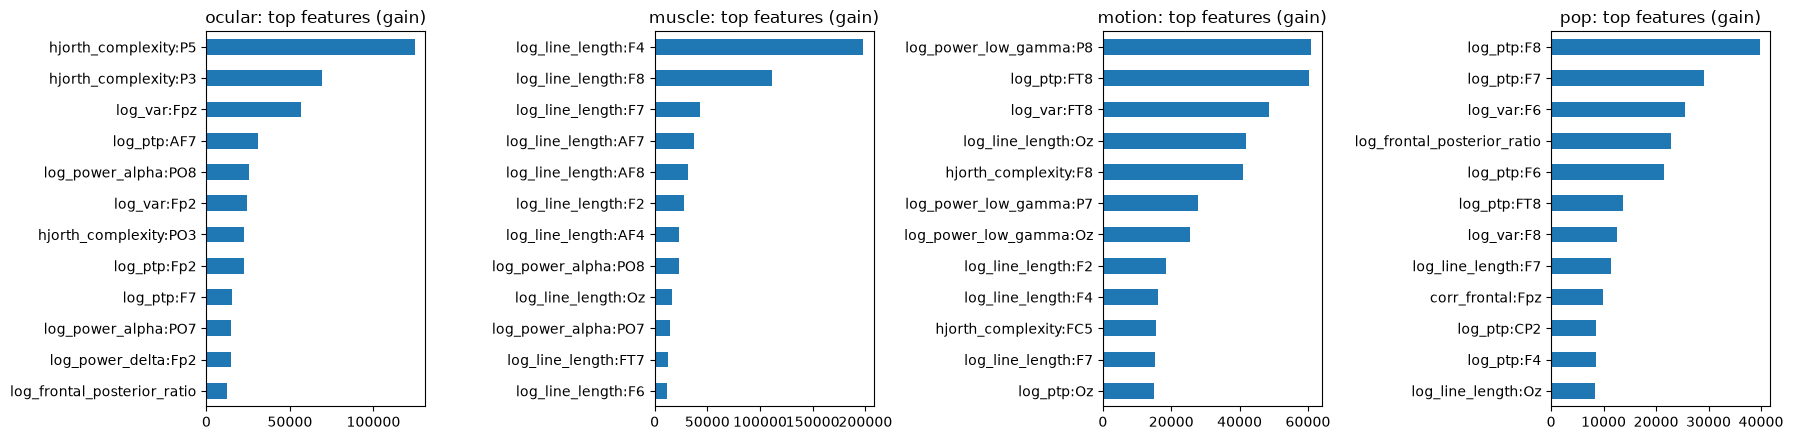

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, target in zip(axes, ("ocular", "muscle", "motion", "pop")):
    model = train.load_model(128.0, "lightgbm", target)
    imp = pd.Series(model.booster_.feature_importance("gain"), index=names).nlargest(12)[::-1]
    imp.plot.barh(ax=ax); ax.set_title(f"{target}: top features (gain)")
fig.tight_layout()

## Detector variants: raw vs per-recording normalised

Open item 12 (decided: train both, choose on Section A Set A). The `norm`
variant robust-z-scores every feature within its recording (PhysioMotion
run, synthetic recording, phantom segment). Cross-validated PR-AUC and false
alarms per hour of clean rest, LightGBM and LDA:

In [7]:
norm = pd.concat([pd.read_csv(det_dir / f"{r}Hz" / "norm" / "cv_metrics.csv") for r in (128, 250)])
both = pd.concat([raw[raw["model"].isin(["lightgbm", "lda"])], norm])
display(both.pivot_table(index="target", columns=["rate", "model", "variant"], values="pr_auc").round(3))
both.pivot_table(index="target", columns=["rate", "model", "variant"], values="false_alarms_per_hour").round(0)

rate        128                           250                       
model       lda        lightgbm           lda        lightgbm       
variant    norm    raw     norm    raw   norm    raw     norm    raw
target                                                              
artifact  0.949  0.945    0.980  0.970  0.948  0.938    0.979  0.969
motion    0.797  0.764    0.928  0.887  0.777  0.735    0.929  0.882
muscle    0.854  0.801    0.955  0.871  0.900  0.846    0.961  0.909
ocular    0.870  0.879    0.939  0.923  0.862  0.861    0.936  0.917
pop       0.282  0.258    0.906  0.866  0.279  0.248    0.899  0.852

rate        128                           250                       
model       lda        lightgbm           lda        lightgbm       
variant    norm    raw     norm    raw   norm    raw     norm    raw
target                                                              
artifact  349.0  453.0    351.0  528.0  384.0  538.0    380.0  618.0
motion    286.0  369.0    156.0  264.0  335.0  426.0    184.0  323.0
muscle    160.0  229.0     48.0  122.0  113.0  210.0     39.0   89.0
ocular    333.0  376.0    286.0  371.0  354.0  428.0    302.0  428.0

## Domain gap on clean Dataset I

Fraction of artifact-free (MWF-cleaned) Dataset I windows flagged at the
default threshold, 128 Hz, Set A noise subjects. Ideally near 0; neither
variant gets there, so the threshold (tuned on Set A, milestone 9) matters.

In [8]:
if RUN_DATASET1:
    flags = pd.concat([transfer.dataset1_clean_flag_rates(variant=v) for v in ("raw", "norm")])
else:
    flags = pd.read_csv(det_dir / "dataset1_clean_flag_rates_128Hz.csv")
display(flags.pivot_table(index=["model", "variant"], columns="target", values="flag_rate", aggfunc="median").round(2))
flags[flags["target"] == "artifact"].pivot_table(index="subject", columns=["model", "variant"], values="flag_rate").round(2)

target            artifact  motion  muscle  ocular   pop
model    variant                                        
lda      norm         0.55    0.26    0.23    0.31  0.33
         raw          0.40    0.10    0.20    0.28  0.11
lightgbm norm         0.68    0.26    0.18    0.35  0.03
         raw          0.65    0.11    0.15    0.37  0.01

model     lda       lightgbm      
variant  norm   raw     norm   raw
subject                           
S10      0.53  0.38     0.66  0.55
S11      0.59  0.60     0.69  0.75
S14      0.54  0.41     0.68  0.53
S4       0.56  0.41     0.68  0.67
S5       0.55  0.58     0.73  0.84
S6       0.54  0.32     0.72  0.63
S7       0.52  0.16     0.72  0.19
S8       0.56  0.24     0.66  0.76

## Transfer to the phantom

Held-out phantom pool (200-300 s of each condition), spline-mapped to
BioSemi 64. AUC of each condition's windows against brain-only windows;
the labels are condition-level, so they are coarse. This comparison is
*between* recordings, so it cannot evaluate the `norm` variant (which
removes recording-level differences by construction; its AUCs sit near
0.5). A within-recording test would label windows from the broadcast
artifact-source waveforms in the ground-truth file.

variant                 norm                              raw                           
condition                All  Eyes Facial  Neck Walking   All  Eyes Facial  Neck Walking
rate model    target                                                                    
128  lda      artifact  0.47  0.53   0.47  0.51    0.49  1.00  0.91   0.93  1.00    0.72
              motion    0.44   NaN    NaN   NaN    0.52  0.99   NaN    NaN   NaN    0.54
              muscle    0.46   NaN   0.43  0.50     NaN  1.00   NaN   0.93  1.00     NaN
              ocular    0.43  0.51    NaN   NaN     NaN  1.00  0.97    NaN   NaN     NaN
     lightgbm artifact  0.36  0.40   0.32  0.50    0.54  0.99  0.86   0.81  0.74    0.54
              motion    0.45   NaN    NaN   NaN    0.57  0.23   NaN    NaN   NaN    0.47
              muscle    0.45   NaN   0.50  0.46     NaN  0.93   NaN   0.87  0.45     NaN
              ocular    0.46  0.51    NaN   NaN     NaN  0.59  0.83    NaN   NaN     NaN
     svm      artifact   NaN   NaN    NaN   NaN     NaN  1.00  0.70   0.89  1.00    0.10
              motion     NaN   NaN    NaN   NaN     NaN  0.88   NaN    NaN   NaN    0.54
              muscle     NaN   NaN    NaN   NaN     NaN  0.98   NaN   0.92  0.92     NaN
              ocular     NaN   NaN    NaN   NaN     NaN  0.91  0.98    NaN   NaN     NaN
250  lda      artifact  0.43  0.54   0.43  0.53    0.50  1.00  0.91   0.94  1.00    0.79
              motion    0.42   NaN    NaN   NaN    0.50  1.00   NaN    NaN   NaN    0.23
              muscle    0.42   NaN   0.38  0.50     NaN  1.00   NaN   0.97  1.00     NaN
              ocular    0.41  0.54    NaN   NaN     NaN  1.00  0.97    NaN   NaN     NaN
     lightgbm artifact  0.29  0.36   0.25  0.46    0.53  0.96  0.60   0.77  0.55    0.46
              motion    0.47   NaN    NaN   NaN    0.51  0.38   NaN    NaN   NaN    0.68
              muscle    0.41   NaN   0.41  0.46     NaN  0.94   NaN   0.95  0.85     NaN
              ocular    0.46  0.54    NaN   NaN     NaN  0.70  0.98    NaN   NaN     NaN
     svm      artifact   NaN   NaN    NaN   NaN     NaN  1.00  0.77   0.90  1.00    0.15
              motion     NaN   NaN    NaN   NaN     NaN  0.84   NaN    NaN   NaN    0.79
              muscle     NaN   NaN    NaN   NaN     NaN  1.00   NaN   0.96  1.00     NaN
              ocular     NaN   NaN    NaN   NaN     NaN  0.97  0.98    NaN   NaN     NaN

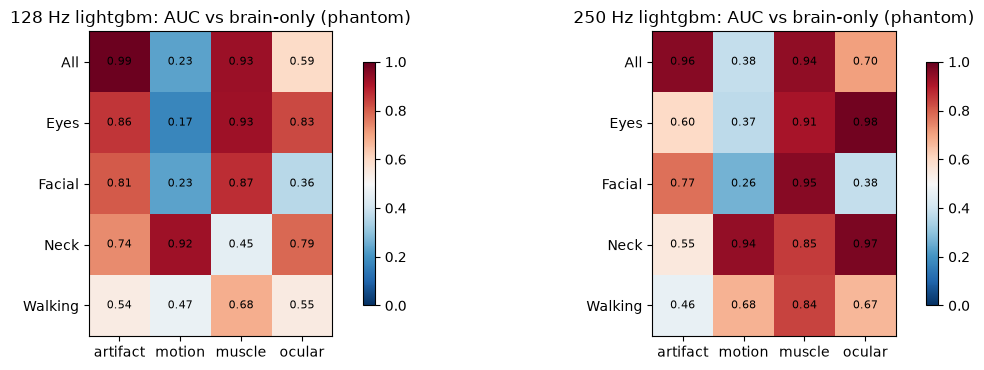

In [9]:
if RUN_TRANSFER:
    tr = pd.concat([transfer.run(), transfer.run(models=("lightgbm", "lda"), variant="norm")])
else:
    tr = pd.concat([pd.read_csv(det_dir / "phantom_transfer.csv").assign(variant="raw"),
                    pd.read_csv(det_dir / "phantom_transfer_norm.csv")])
fig = transfer.plot(tr[tr["variant"] == "raw"], "lightgbm")
tr[tr["source_on_for_target"]].pivot_table(index=["rate", "model", "target"], columns=["variant", "condition"],
                                           values="auc_vs_brain").round(2)